#### Do the neighbors of a conversion drift toward what it became?

Take every true positive from the out of fold predictions of `results/tcn_batch_size_2048` at p >= 0.50 and call it an anchor. Its 2024 AlphaEarth embedding is what the pixel looks like after it converted to developed. For each anchor, look at its 8 adjacent pixels, split them into TP, FP, TN and FN by their own prediction, and take the L2 distance from the anchor's 2024 embedding to the neighbor's 2017, 2018 and 2019 embeddings. The control is the anchor against itself: its own 2017, 2018 and 2019 embeddings against its own 2024 embedding.

If the neighborhood is already on its way to becoming developed before 2019, those distances should shrink from 2017 to 2019. The control says how much of that a pixel which did convert shows on its own.

Two things to keep in mind when reading this. First, which group a neighbor lands in depends on how the model scored its 2017 to 2019 embeddings, so FP neighbors were partly selected for already looking like conversions. The TP against FN split is cleaner, since both groups really converted and differ only in the call. Second, the 2024 tiles and the 2017 to 2019 arrays came from different exports with different 8 bit encodings, see below. Each is decoded with its own scale, and the year to year trend is compared within the 2017 to 2019 embeddings, so a small fixed offset against 2024 would not create a trend.

### Setup

Negatives are restricted to `label_raw == 0`, remained wetland, the same as `neighbor_comparison.ipynb`. `label.npy` folds class 2 (converted to something other than developed) into 0, but those pixels did change, so they are dropped as neighbors and counted separately. Outputs go to `data/embedding_trajectory_2019_2024/tcn_batch_size_2048`.

In [1]:
import glob
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import arrays as array_io
from export_val_predictions import fold_rows
from features import YEARS_2017_2019, emb_cols
from folds import assign_folds
from population_stats import load_population_stats

RUN_DIR = ROOT / "results/tcn_batch_size_2048"
ARRAY_DIR = ROOT / "data/arrays_2019_2024"
POP_STATS_PATH = ROOT / "data/population_stats_2019_2024.json"
AE_2024_DIR = ROOT / "data/alphaearth_embeddings/alphaearth_30m"
OUT_DIR = ROOT / "data/embedding_trajectory_2019_2024/tcn_batch_size_2048"
OUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5
YEARS = YEARS_2017_2019
EMB_COLUMNS = emb_cols(YEARS)
EMB_YEAR = {yr: np.array([i for i, c in enumerate(EMB_COLUMNS) if c.endswith(f"_{yr}")]) for yr in YEARS}
assert all(len(ix) == 64 for ix in EMB_YEAR.values())

N_BANDS = 64
TILE_PX = 2000
PIXEL_M = 30
# The 2024 export (GEE/export_alphaearth_30m.py) writes byte = v * 127.5 + 127.5,
# not the (byte - 128) / 127 scheme the 2017 to 2019 tifs used. Decoding 2024 with
# the old scale would shift every element by about 0.004, about 0.03 in L2.
AE_2024_OFFSET = 127.5
AE_2024_SCALE = 127.5

### Out of fold probabilities

Same stitching as `neighbor_comparison.ipynb`: `fold_rows` rebuilds each fold's validation order and the saved labels are checked element by element against `label.npy`.

In [2]:
arrays, array_manifest = array_io.load_arrays(
    ARRAY_DIR, optional=("label_raw", "rowcol", "xy"), emb_columns=EMB_COLUMNS
)
with open(RUN_DIR / "manifest.json") as fh:
    run_manifest = json.load(fh)

y = arrays["label"].astype(bool)
label_raw = np.asarray(arrays["label_raw"])
n_rows = array_manifest["total_rows"]

pop = load_population_stats(POP_STATS_PATH)
fold_assignment = assign_folds(pop["block_row_counts"], run_manifest["n_splits"], run_manifest["seed"])
fold_code = array_io.fold_of_code(array_manifest, fold_assignment)

prob = np.full(n_rows, np.nan, dtype=np.float32)
fold = np.full(n_rows, -1, dtype=np.int8)
for k in range(run_manifest["n_splits"]):
    rows = fold_rows(arrays, array_manifest, fold_code, k)
    with np.load(RUN_DIR / f"fold_{k}" / "val_preds.npz") as npz:
        probs, labels = npz["probs"], npz["labels"]
    assert len(rows) == len(probs), f"fold {k}: {len(rows):,} rebuilt rows against {len(probs):,} predictions"
    assert np.array_equal(y[rows].astype(np.float32), labels), f"fold {k}: row order does not match saved labels"
    assert (fold[rows] == -1).all(), f"fold {k} overlaps an earlier fold"
    prob[rows] = probs
    fold[rows] = k
    print(f"fold {k}: {len(rows):>12,} rows, {int(labels.sum()):>7,} positives")

assert (fold >= 0).all(), "some pixels were never in a validation fold"
print(f"\n{n_rows:,} pixels scored, {int(y.sum()):,} positives ({y.mean():.4%})")

fold 0:   11,866,780 rows,  29,390 positives


fold 1:   11,845,125 rows,  39,123 positives


fold 2:   11,841,089 rows,  30,462 positives


fold 3:   11,854,236 rows,  30,405 positives


fold 4:   11,860,101 rows,  36,528 positives

59,267,331 pixels scored, 165,908 positives (0.2799%)


### Confusion counts at p >= 0.50

0.5 matches `fold_summary.csv` and the per fold confusion matrices. There is no calibration step, so it is a reference point, not a principled operating point.

In [3]:
hit = prob >= THRESHOLD
tp, fp = int((hit & y).sum()), int((hit & ~y).sum())
fn, tn = int((~hit & y).sum()), int((~hit & ~y).sum())
pd.DataFrame([{
    "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    "precision": round(tp / (tp + fp), 3), "recall": round(tp / (tp + fn), 3),
    "positive rate": f"{y.mean():.4%}",
}], index=[f"p >= {THRESHOLD:.2f}"])

,TP,FP,FN,TN,precision,recall,positive rate
p >= 0.50,48669,324386,117239,58777037,0.13,0.293,0.2799%


### Neighbor lookup

`rowcol` is one global 30 m grid, so a neighbor is an offset in key space plus a `searchsorted`. Only 2019 wetland pixels are in the arrays, so offsets that land on uplands, water or existing development come back as -1 and have no prediction to group. The row width is padded by one column on each side so col plus 1 at the east edge cannot wrap into the next row.

In [4]:
rc = np.asarray(arrays["rowcol"]).astype(np.int64)
ROW0, COL0 = rc.min(axis=0) - 1
W = int(rc[:, 1].max() - COL0) + 2
key = (rc[:, 0] - ROW0) * W + (rc[:, 1] - COL0)
key_order = np.argsort(key, kind="stable").astype(np.int32)
key_sorted = key[key_order]
assert np.all(np.diff(key_sorted) > 0), "rowcol has duplicate pixels"
del rc


def lookup(q):
    i = np.searchsorted(key_sorted, q)
    np.minimum(i, len(key_sorted) - 1, out=i)
    return np.where(key_sorted[i] == q, key_order[i], -1)


OFFSETS = np.array([(dr, dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0)])
NEIGHBOR_STEP = OFFSETS[:, 0] * W + OFFSETS[:, 1]

check = np.random.default_rng(0).choice(n_rows, 1_000_000, replace=False)
assert np.array_equal(lookup(key[check]), check)
del check

anchors = np.flatnonzero(y & hit)
print(f"{len(anchors):,} TP anchors")

48,669 TP anchors


### Anchor 2024 embeddings

The 2024 tiles are on the NLCD grid in EPSG:5070. Each anchor's stored `xy` is a pixel center, so it has to land exactly half a pixel inside a tile cell; anything else means the tile grid and the array grid disagree and the lookup would pull a neighbor's vector. Anchors over nodata (all 64 bands at byte 0) or outside every tile are dropped and counted.

The norm check at the end is a sanity check on the decode: AlphaEarth vectors are unit length, so both the 2019 and the 2024 norms should sit near 1.

In [5]:
xy = np.asarray(arrays["xy"][anchors]).astype(np.float64)
emb_2024 = np.full((len(anchors), N_BANDS), np.nan, dtype=np.float32)
tile_files = sorted(glob.glob(str(AE_2024_DIR / "AlphaEarth30m_Florida_2024_*.tif")))
assert tile_files, f"no 2024 tiles in {AE_2024_DIR}"

for path in tile_files:
    with rasterio.open(path) as src:
        assert (src.count, src.width, src.height) == (N_BANDS, TILE_PX, TILE_PX), Path(path).name
        t = src.transform
        assert t.a == PIXEL_M and t.e == -PIXEL_M, f"{Path(path).name}: not a 30 m grid"
        fc = (xy[:, 0] - t.c) / PIXEL_M
        fr = (t.f - xy[:, 1]) / PIXEL_M
        inside = (fc >= 0) & (fc < TILE_PX) & (fr >= 0) & (fr < TILE_PX)
        if not inside.any():
            continue
        assert np.allclose(fc[inside] % 1, 0.5) and np.allclose(fr[inside] % 1, 0.5), (
            f"{Path(path).name}: pixel centers are not half a pixel into the tile grid"
        )
        tc, tr = np.floor(fc[inside]).astype(np.intp), np.floor(fr[inside]).astype(np.intp)
        r0, r1, c0, c1 = tr.min(), tr.max() + 1, tc.min(), tc.max() + 1
        block = src.read(window=((r0, r1), (c0, c1)))
        codes = block[:, tr - r0, tc - c0].T
        nodata = (codes == 0).all(axis=1)
        vals = (codes.astype(np.float32) - AE_2024_OFFSET) / AE_2024_SCALE
        vals[nodata] = np.nan
        emb_2024[np.flatnonzero(inside)] = vals

has_2024 = ~np.isnan(emb_2024).any(axis=1)
print(f"{int(has_2024.sum()):,} of {len(anchors):,} anchors have a 2024 embedding, "
      f"{int((~has_2024).sum()):,} dropped (nodata or outside every tile)")
anchors, emb_2024 = anchors[has_2024], emb_2024[has_2024]

e19 = arrays["emb"][anchors[:5000]][:, EMB_YEAR[2019]].astype(np.float32)
print(f"median norm, 2019: {np.median(np.linalg.norm(e19, axis=1)):.3f}, "
      f"2024: {np.median(np.linalg.norm(emb_2024[:5000], axis=1)):.3f}")
del xy, e19

48,669 of 48,669 anchors have a 2024 embedding, 0 dropped (nodata or outside every tile)
median norm, 2019: 0.993, 2024: 0.984


### Pairs and distances

Each (anchor, neighbor) pair is one observation. A neighbor that touches three anchors shows up three times, once against each anchor's 2024 vector, and a TP neighbor is usually an anchor itself as well. Big development patches put many anchors next to each other, so they carry more weight than small ones.

The anchor control gets one row per anchor, with the anchor as its own neighbor. Embeddings are float16 on disk and the distance is taken in float32. `cross_fold` marks pairs where the anchor and its neighbor were scored by different fold models, which happens along block edges.

In [6]:
nb = lookup(key[anchors][:, None] + NEIGHBOR_STEP)
slot_counts = {
    "neighbor slots": nb.size,
    "no prediction (not 2019 wetland)": int((nb < 0).sum()),
}
ai, oi = np.nonzero(nb >= 0)
a_ix, n = ai, nb[ai, oi]
slot_counts["dropped, class 2"] = int((label_raw[n] == 2).sum())
keep = label_raw[n] != 2
a_ix, n = a_ix[keep], n[keep]

group = np.select([y[n] & hit[n], y[n], hit[n]], ["TP", "FN", "FP"], "TN")
for g in ("TP", "FP", "TN", "FN"):
    slot_counts[f"{g} neighbors"] = int((group == g).sum())

# Anchor control rides along as a fifth group with the anchor as its own neighbor.
a_ix = np.concatenate([a_ix, np.arange(len(anchors))])
n = np.concatenate([n, anchors])
group = np.concatenate([group, np.full(len(anchors), "Anchor")])

need, inv = np.unique(n, return_inverse=True)
ev = arrays["emb"][need].astype(np.float32)[inv]
pairs = pd.DataFrame({"anchor": anchors[a_ix], "neighbor": n, "group": group})
for yr in YEARS:
    pairs[f"l2_{yr}"] = np.linalg.norm(emb_2024[a_ix] - ev[:, EMB_YEAR[yr]], axis=1)
pairs["change_2017_to_2019"] = pairs["l2_2019"] - pairs["l2_2017"]
pairs["cross_fold"] = fold[pairs.anchor.to_numpy()] != fold[pairs.neighbor.to_numpy()]
del ev, need, inv

pairs.to_parquet(OUT_DIR / f"pairs_t{THRESHOLD:.3f}.parquet", index=False)
pd.Series(slot_counts, name="count").to_frame()

,count
neighbor slots,389352
no prediction (not 2019 wetland),157552
"dropped, class 2",1192
TP neighbors,135046
FP neighbors,38160
TN neighbors,23413
FN neighbors,33989


In [7]:
with open(OUT_DIR / "provenance.json", "w") as fh:
    json.dump({
        "run_dir": str(RUN_DIR.relative_to(ROOT)),
        "run_seed": run_manifest["seed"],
        "run_n_splits": run_manifest["n_splits"],
        "run_manifest_arrays_path": run_manifest["arrays"]["path"],
        "array_dir": str(ARRAY_DIR.relative_to(ROOT)),
        "array_built_utc": array_manifest["built_utc"],
        "array_git_commit": array_manifest["git_commit"],
        "array_source_parquet": array_manifest["source_parquet_path"],
        "embedding_2017_2019": "AlphaEarth annual from emb.npy, float16, decoded upstream as (byte - 128) / 127",
        "embedding_2024": "GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL via GEE/export_alphaearth_30m.py, "
                          "uint8 tiles decoded as (byte - 127.5) / 127.5",
        "embedding_2024_dir": str(AE_2024_DIR.relative_to(ROOT)),
        "threshold": THRESHOLD,
        "neighborhood": "8 connected, r = 1, 30 m",
        "negative_definition": "label_raw == 0, class 2 neighbors dropped",
        "distance": "L2 in float32 from anchor 2024 to neighbor 2017, 2018, 2019",
        "counting_unit": "one row per (anchor, neighbor) pair; Anchor group is the anchor against itself",
    }, fh, indent=2)

### Summary table

Per group: how many anchors have at least one such neighbor, how many pairs there are, the median and interquartile range of the distance in each year, the median of the paired change from 2017 to 2019 (negative means the neighbor got closer to the anchor's 2024 embedding), and the share of pairs that got closer. Saved to `l2_summary.csv`.

In [8]:
GROUP_ORDER = ["Anchor", "TP", "FN", "FP", "TN"]
rows = []
for g in GROUP_ORDER:
    p = pairs[pairs.group == g]
    row = {"group": g, "n_anchors": p.anchor.nunique(), "n_pairs": len(p)}
    for yr in YEARS:
        d = p[f"l2_{yr}"]
        row[f"median {yr}"] = d.median()
        row[f"IQR {yr}"] = d.quantile(0.75) - d.quantile(0.25)
    row["median change 2017 to 2019"] = p.change_2017_to_2019.median()
    row["share closer by 2019"] = (p.change_2017_to_2019 < 0).mean()
    row["share cross fold"] = p.cross_fold.mean()
    rows.append(row)
l2_summary = pd.DataFrame(rows).set_index("group")
l2_summary.to_csv(OUT_DIR / "l2_summary.csv")
l2_summary.round(3)

,n_anchors,n_pairs,median 2017,IQR 2017,median 2018,IQR 2018,median 2019,IQR 2019,median change 2017 to 2019,share closer by 2019,share cross fold
group,,,,,,,,,,,
Anchor,48669,48669,0.695,0.385,0.691,0.395,0.659,0.399,-0.023,0.701,0.000
TP,39292,135046,0.820,0.283,0.826,0.289,0.801,0.290,-0.016,0.654,0.006
FN,16085,33989,0.810,0.272,0.809,0.276,0.784,0.274,-0.016,0.665,0.010
FP,18820,38160,0.572,0.292,0.568,0.293,0.535,0.285,-0.027,0.727,0.004
TN,12325,23413,0.614,0.245,0.610,0.250,0.580,0.244,-0.025,0.718,0.007


### Figures

The first figure is the median distance from the anchor's 2024 embedding in each year, one line per group, with the anchor against itself as the control. The interquartile ranges are in the table above rather than drawn as bands, since five overlapping bands are unreadable.

The second is the paired change from 2017 to 2019 per group, as box plots without outliers. Left of zero means the pixel's embedding moved toward the anchor's 2024 embedding. Pair counts per group are in the summary table.

In [9]:
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "legend.fontsize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Okabe Ito, same colors per group as neighbor_comparison.ipynb, with the control in black.
STYLE = {
    "Anchor": dict(color="#000000", label="Anchor itself (control)"),
    "TP": dict(color="#009E73", label="TP neighbors"),
    "FN": dict(color="#CC79A7", label="FN neighbors"),
    "FP": dict(color="#D55E00", label="FP neighbors"),
    "TN": dict(color="#0072B2", label="TN neighbors"),
}


def save(fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    fig.savefig(out_path.with_suffix(".pdf"))
    plt.show()

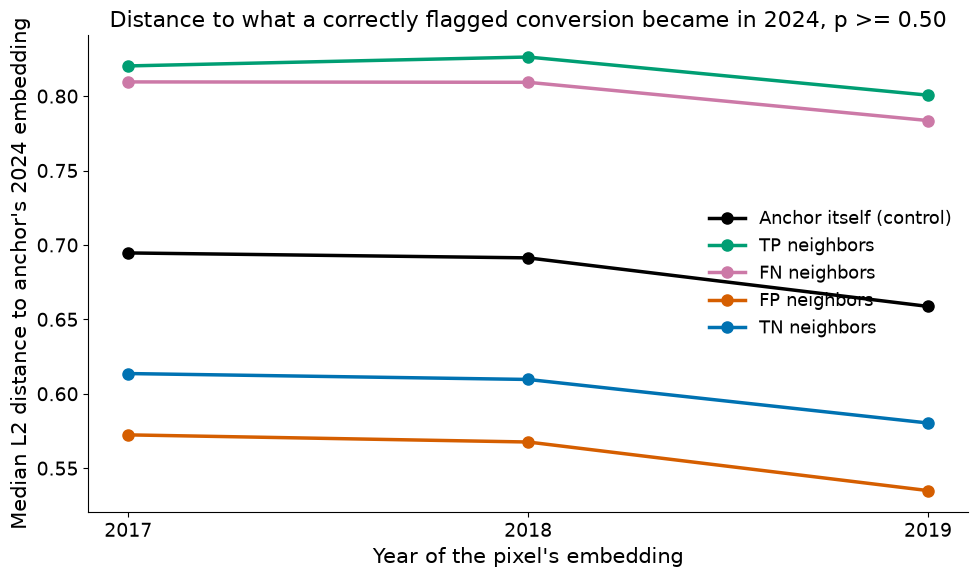

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
for g in GROUP_ORDER:
    med = [l2_summary.loc[g, f"median {yr}"] for yr in YEARS]
    ax.plot(YEARS, med, marker="o", lw=2.5, ms=8, **STYLE[g])
ax.set_xticks(YEARS)
ax.set_xlabel("Year of the pixel's embedding")
ax.set_ylabel("Median L2 distance to anchor's 2024 embedding")
ax.set_title(f"Distance to what a correctly flagged conversion became in 2024, p >= {THRESHOLD:.2f}")
ax.legend(frameon=False)
save(fig, OUT_DIR / f"median_l2_by_year_t{THRESHOLD:.3f}.png")

/tmp/ipykernel_5232/2085916419.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, showfliers=False, widths=0.6, patch_artist=True,


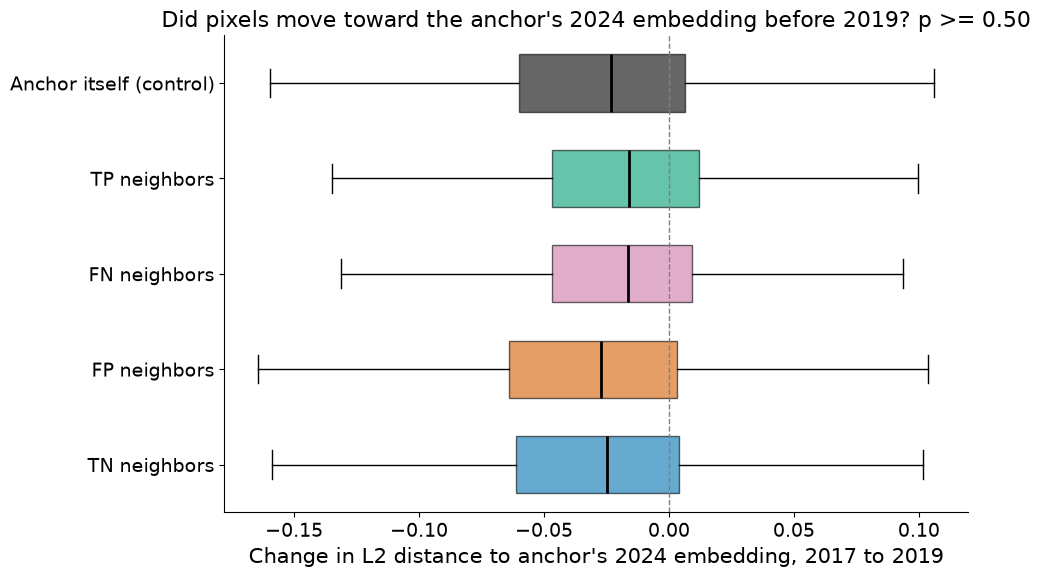

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
data = [pairs.loc[pairs.group == g, "change_2017_to_2019"].to_numpy() for g in GROUP_ORDER]
bp = ax.boxplot(data, vert=False, showfliers=False, widths=0.6, patch_artist=True,
                medianprops=dict(color="black", lw=2))
for patch, g in zip(bp["boxes"], GROUP_ORDER):
    patch.set_facecolor(STYLE[g]["color"])
    patch.set_alpha(0.6)
ax.set_yticks(range(1, len(GROUP_ORDER) + 1), [STYLE[g]["label"] for g in GROUP_ORDER])
ax.invert_yaxis()
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_xlabel("Change in L2 distance to anchor's 2024 embedding, 2017 to 2019")
ax.set_title(f"Did pixels move toward the anchor's 2024 embedding before 2019? p >= {THRESHOLD:.2f}")
save(fig, OUT_DIR / f"l2_change_2017_to_2019_t{THRESHOLD:.3f}.png")

### Density histograms of the change from 2017 to 2019

The same paired change as the box plots, split across two histograms because the groups overlap heavily. The first holds the neighbors that really converted, TP and FN, and the second the neighbors that remained wetland, FP and TN, so each histogram compares the model's call within one true outcome. The anchor against itself is drawn as a black outline on both as a shared reference. Y is density, so each histogram has area 1 and shapes compare even though pair counts differ; the counts are in the summary table. Bins are shared across both figures and cut at the 0.5th and 99.5th percentiles of all changes so the long tails do not squash the middle. Left of the dashed line means the pixel moved toward the anchor's 2024 embedding.

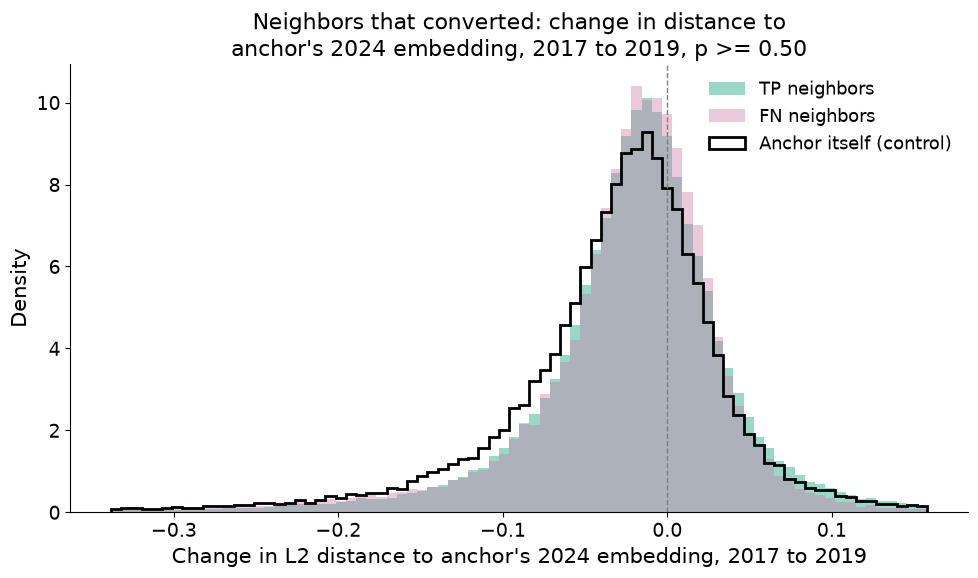

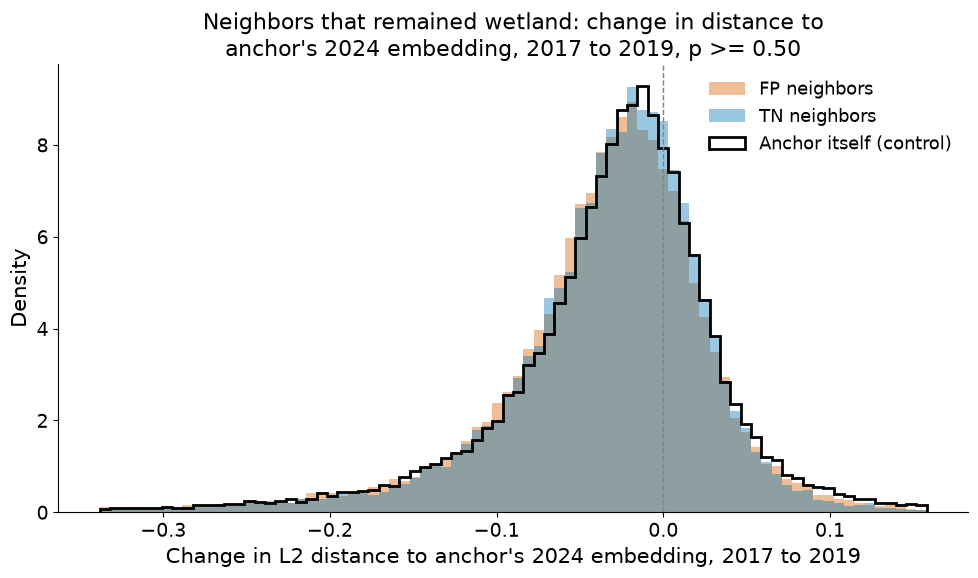

In [12]:
lo, hi = pairs.change_2017_to_2019.quantile([0.005, 0.995])
change_bins = np.linspace(lo, hi, 81)


def plot_change_hist(kinds, title, out_path):
    fig, ax = plt.subplots(figsize=(10, 6))
    for g in kinds:
        ax.hist(pairs.loc[pairs.group == g, "change_2017_to_2019"], bins=change_bins,
                density=True, alpha=0.4, **STYLE[g])
    ax.hist(pairs.loc[pairs.group == "Anchor", "change_2017_to_2019"], bins=change_bins,
            density=True, histtype="step", lw=2, **STYLE["Anchor"])
    ax.axvline(0, color="grey", lw=1, ls="--")
    ax.set_xlabel("Change in L2 distance to anchor's 2024 embedding, 2017 to 2019")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(frameon=False)
    save(fig, out_path)


plot_change_hist(
    ["TP", "FN"],
    f"Neighbors that converted: change in distance to\nanchor's 2024 embedding, 2017 to 2019, p >= {THRESHOLD:.2f}",
    OUT_DIR / f"l2_change_hist_tp_fn_t{THRESHOLD:.3f}.png",
)
plot_change_hist(
    ["FP", "TN"],
    f"Neighbors that remained wetland: change in distance to\nanchor's 2024 embedding, 2017 to 2019, p >= {THRESHOLD:.2f}",
    OUT_DIR / f"l2_change_hist_fp_tn_t{THRESHOLD:.3f}.png",
)